#  Advanced Exploratory Data Analysis

## Borough Comparisons, Price Trends and Spatial Inequality

This notebook extends the initial exploratory analysis by examining differences in house-price levels, growth, volatility and market activity across London areas.

The analysis investigates whether price inequality between areas changed over time and whether boroughs responded differently during major market periods, including the 2008 financial crisis.

Both nominal and inflation-adjusted house prices are considered.

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')

In [6]:
# adjust this file path as required depending on the local directory structure
file_path = '/london_housing_feature_engineered.csv'

df = pd.read_csv(file_path)

df.head()

,date,area,average_price,code,houses_sold,no_of_crimes,borough_flag,cpi_index_2015_100,cpi_yoy_pct,cpi_mom_pct,bank_rate_monthly_avg,year,month,quarter,month_gap,month_name,time_index,month_sin,month_cos,price_lag_1,price_lag_3,price_lag_6,price_lag_12,houses_sold_lag_1,houses_sold_lag_3,houses_sold_lag_12,crime_lag_1,crime_lag_12,price_rolling_mean_3,price_rolling_mean_6,price_rolling_mean_12,price_rolling_std_3,price_rolling_std_12,houses_sold_rolling_mean_3,houses_sold_rolling_mean_12,price_mom_growth_pct,price_3m_growth_pct,price_yoy_growth_pct,price_mom_growth_lag_1,price_3m_growth_lag_1,price_yoy_growth_lag_1,houses_sold_mom_growth_pct,houses_sold_yoy_growth_pct,houses_sold_mom_growth_lag_1,houses_sold_yoy_growth_lag_1,real_price_2015,real_price_lag_1,real_price_lag_12,real_price_rolling_mean_12,cpi_lag_1,cpi_lag_3,cpi_lag_12,bank_rate_lag_1,bank_rate_lag_3,bank_rate_lag_12,bank_rate_change_1m,bank_rate_change_12m,bank_rate_change_1m_lag_1,bank_rate_change_12m_lag_1,post_2008,pandemic_2020
0,2001-01-01,barking and dagenham,82343,E09000002,215.00,"1,771.00",1,66.18,2.71,-0.63,6.00,2001,1,1,NaN,Jan,1,0.50,0.87,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"124,424.34",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,0
1,2001-02-01,barking and dagenham,83266,E09000002,238.00,"1,600.00",1,66.52,2.68,0.52,5.81,2001,2,1,31.00,Feb,2,0.87,0.50,"82,343.00",NaN,NaN,NaN,215.00,NaN,NaN,"1,771.00",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.12,NaN,NaN,NaN,NaN,NaN,10.70,NaN,NaN,NaN,"125,170.01","124,424.34",NaN,NaN,66.18,NaN,NaN,6.00,NaN,NaN,-0.19,NaN,NaN,NaN,0,0
2,2001-03-01,barking and dagenham,84058,E09000002,274.00,"1,759.00",1,66.60,2.26,0.12,5.75,2001,3,1,28.00,Mar,3,1.00,0.00,"83,266.00",NaN,NaN,NaN,238.00,NaN,NaN,"1,600.00",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.95,NaN,NaN,1.12,NaN,NaN,15.13,NaN,10.70,NaN,"126,211.77","125,170.01",NaN,NaN,66.52,NaN,NaN,5.81,NaN,NaN,-0.06,NaN,-0.19,NaN,0,0
3,2001-04-01,barking and dagenham,83965,E09000002,241.00,"1,643.00",1,66.95,1.77,0.53,5.53,2001,4,2,31.00,Apr,4,0.87,-0.50,"84,058.00","82,343.00",NaN,NaN,274.00,215.00,NaN,"1,759.00",NaN,"83,222.33",NaN,NaN,858.33,NaN,242.33,NaN,-0.11,1.97,NaN,0.95,NaN,NaN,-12.04,NaN,15.13,NaN,"125,407.53","126,211.77",NaN,NaN,66.60,66.18,NaN,5.75,6.00,NaN,-0.22,NaN,-0.06,NaN,0,0
4,2001-05-01,barking and dagenham,85124,E09000002,283.00,"1,809.00",1,67.38,2.05,0.63,5.32,2001,5,2,30.00,May,5,0.50,-0.87,"83,965.00","83,266.00",NaN,NaN,241.00,238.00,NaN,"1,643.00",NaN,"83,763.00",NaN,NaN,432.92,NaN,251.00,NaN,1.38,2.23,NaN,-0.11,1.97,NaN,17.43,NaN,-12.04,NaN,"126,343.03","125,407.53",NaN,NaN,66.95,66.52,NaN,5.53,5.81,NaN,-0.21,NaN,-0.22,NaN,0,0


In [7]:
df['date'] = pd.to_datetime(df['date'])

df = (
    df.sort_values(['area', 'date'])
      .reset_index(drop=True)
)

In [8]:
print("Dataset shape:", df.shape)
print("Date range:", df['date'].min(), "to", df['date'].max())
print("Number of areas:", df['area'].nunique())

Dataset shape: (7375, 61)
Date range: 2001-01-01 00:00:00 to 2019-11-01 00:00:00
Number of areas: 33


###Restrict the analysis to London boroughs

In [9]:
sorted(df['area'].dropna().unique())

['barking and dagenham',
 'barnet',
 'bexley',
 'brent',
 'bromley',
 'camden',
 'city of london',
 'croydon',
 'ealing',
 'enfield',
 'greenwich',
 'hackney',
 'hammersmith and fulham',
 'haringey',
 'harrow',
 'havering',
 'hillingdon',
 'hounslow',
 'islington',
 'kensington and chelsea',
 'kingston upon thames',
 'lambeth',
 'lewisham',
 'merton',
 'newham',
 'redbridge',
 'richmond upon thames',
 'southwark',
 'sutton',
 'tower hamlets',
 'waltham forest',
 'wandsworth',
 'westminster']

In [10]:
borough_df = df[df['borough_flag'] == 1].copy()

In [11]:
print("Number of borough areas:", borough_df['area'].nunique())
print(sorted(borough_df['area'].unique()))

Number of borough areas: 33
['barking and dagenham', 'barnet', 'bexley', 'brent', 'bromley', 'camden', 'city of london', 'croydon', 'ealing', 'enfield', 'greenwich', 'hackney', 'hammersmith and fulham', 'haringey', 'harrow', 'havering', 'hillingdon', 'hounslow', 'islington', 'kensington and chelsea', 'kingston upon thames', 'lambeth', 'lewisham', 'merton', 'newham', 'redbridge', 'richmond upon thames', 'southwark', 'sutton', 'tower hamlets', 'waltham forest', 'wandsworth', 'westminster']


In [ ]:
non_borough_areas = [
    'england',
    'london',
    'inner london',
    'outer london',
    'south east',
    'south west',
    'east of england',
    'north east',
    'north west',
    'west midlands',
    'east midlands',
    'yorks and the humber'
]

borough_df = df[
    ~df['area'].str.lower().isin(non_borough_areas) # keep only London borough rows by excluding non-borough aggregate areas
].copy()

###borough summary table

In [13]:
borough_summary = (
    borough_df.groupby('area')
    .agg(
        mean_price=('average_price', 'mean'),
        median_price=('average_price', 'median'),
        minimum_price=('average_price', 'min'),
        maximum_price=('average_price', 'max'),
        price_std=('average_price', 'std'),
        mean_houses_sold=('houses_sold', 'mean'),
        first_date=('date', 'min'),
        last_date=('date', 'max'),
        observations=('average_price', 'count')
    )
    .sort_values('mean_price', ascending=False)
)

display(borough_summary.head(10))

,mean_price,median_price,minimum_price,maximum_price,price_std,mean_houses_sold,first_date,last_date,observations
area,,,,,,,,,
kensington and chelsea,"888,639.07","832,753.00",394886,1463378,"337,981.16",226.21,2001-01-01,2019-11-01,227
westminster,"654,077.12","599,540.00",276752,1117408,"258,199.56",324.07,2001-01-01,2019-11-01,227
camden,"559,213.34","524,202.00",265515,881212,"197,102.20",234.71,2001-01-01,2019-11-01,227
hammersmith and fulham,"527,594.00","501,662.00",259723,781175,"169,608.83",235.25,2001-01-01,2019-11-01,227
richmond upon thames,"451,974.00","426,903.00",229361,682854,"140,395.39",303.67,2001-01-01,2019-11-01,227
islington,"436,635.84","408,596.00",202308,677798,"150,447.05",226.93,2001-01-01,2019-11-01,227
wandsworth,"409,200.41","381,421.00",192543,633826,"136,242.97",522.50,2001-01-01,2019-11-01,227
barnet,"361,831.45","338,033.00",175475,549401,"108,395.28",421.76,2001-01-01,2019-11-01,227
haringey,"349,932.92","319,010.00",154406,568649,"125,496.38",249.82,2001-01-01,2019-11-01,227


In [14]:
borough_summary['coefficient_of_variation'] = (
    borough_summary['price_std']
    / borough_summary['mean_price']
)

display(
    borough_summary.sort_values(
        'coefficient_of_variation',
        ascending=False
    ).head(10)
)

,mean_price,median_price,minimum_price,maximum_price,price_std,mean_houses_sold,first_date,last_date,observations,coefficient_of_variation
area,,,,,,,,,,
westminster,"654,077.12","599,540.00",276752,1117408,"258,199.56",324.07,2001-01-01,2019-11-01,227,0.39
hackney,"345,281.43","306,799.00",139102,575846,"133,944.77",220.74,2001-01-01,2019-11-01,227,0.39
kensington and chelsea,"888,639.07","832,753.00",394886,1463378,"337,981.16",226.21,2001-01-01,2019-11-01,227,0.38
waltham forest,"264,310.51","225,477.00",108104,447630,"99,558.40",292.59,2001-01-01,2019-11-01,227,0.38
haringey,"349,932.92","319,010.00",154406,568649,"125,496.38",249.82,2001-01-01,2019-11-01,227,0.36
southwark,"330,712.06","302,376.00",154901,535685,"117,995.80",332.10,2001-01-01,2019-11-01,227,0.36
lewisham,"259,659.43","229,261.00",112637,423063,"92,538.24",352.17,2001-01-01,2019-11-01,227,0.36
lambeth,"334,458.85","303,699.00",155593,532804,"118,629.64",381.18,2001-01-01,2019-11-01,227,0.35
camden,"559,213.34","524,202.00",265515,881212,"197,102.20",234.71,2001-01-01,2019-11-01,227,0.35


Standard deviation measures absolute variation.
The coefficient of variation compares variation relative to the borough’s average price.
A high coefficient does not automatically mean risk; it may also reflect rapid long-term growth.

###Rank boroughs by latest available price

In [15]:
latest_date = borough_df['date'].max()

latest_prices = (
    borough_df[borough_df['date'] == latest_date]
    [['area', 'average_price']]
    .sort_values('average_price', ascending=False)
    .reset_index(drop=True)
)

latest_prices['rank'] = np.arange(1, len(latest_prices) + 1)

display(latest_prices.head(10))
display(latest_prices.tail(10))

,area,average_price,rank
0,kensington and chelsea,1193336,1
1,westminster,955615,2
2,camden,818880,3
3,hammersmith and fulham,718071,4
4,richmond upon thames,649756,5
5,islington,629164,6
6,wandsworth,600835,7
7,hackney,562039,8
8,haringey,561283,9
9,barnet,523582,10


,area,average_price,rank
22,hounslow,410452,23
23,hillingdon,408048,24
24,greenwich,397157,25
25,enfield,393860,26
26,sutton,375450,27
27,croydon,367458,28
28,havering,366351,29
29,newham,365400,30
30,bexley,334711,31
31,barking and dagenham,305882,32


In [16]:
print("Latest date:", latest_date)
print("Areas available:", len(latest_prices))
print("Total boroughs:", borough_df['area'].nunique())

Latest date: 2019-11-01 00:00:00
Areas available: 32
Total boroughs: 33


In [17]:
latest_prices = (
    borough_df.sort_values('date')
    .groupby('area')
    .tail(1)
    [['area', 'date', 'average_price']]
    .sort_values('average_price', ascending=False)
    .reset_index(drop=True)
)

latest_prices['rank'] = np.arange(1, len(latest_prices) + 1)

### Ten most expensive boroughs

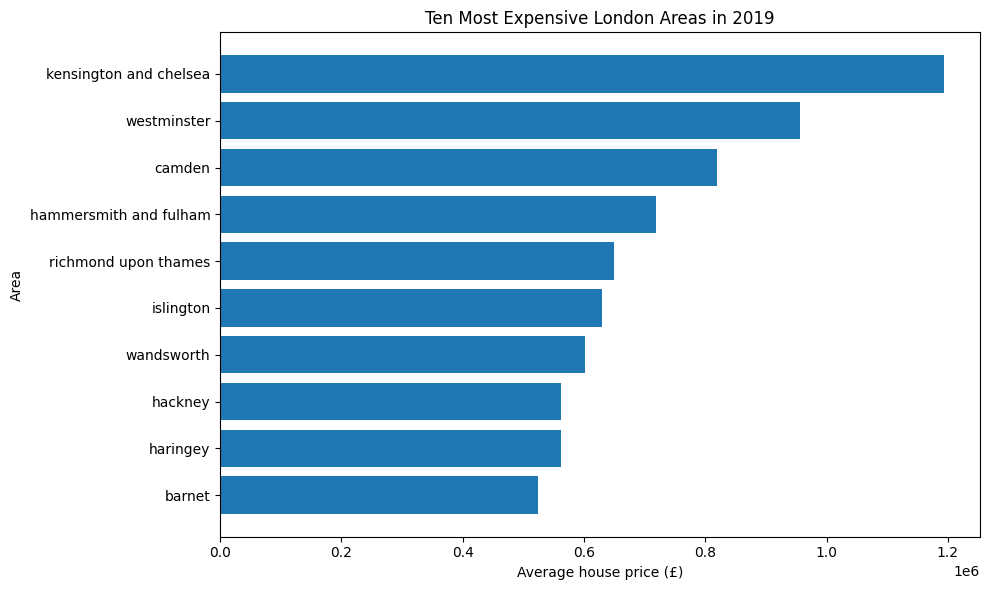

In [18]:
top10_latest = latest_prices.head(10).sort_values(
    'average_price'
)

plt.figure(figsize=(10, 6))

plt.barh(
    top10_latest['area'],
    top10_latest['average_price']
)

plt.title(
    f'Ten Most Expensive London Areas in '
    f'{latest_prices["date"].max().year}'
    if 'date' in latest_prices.columns
    else 'Ten Most Expensive London Areas'
)

plt.xlabel('Average house price (£)')
plt.ylabel('Area')
plt.tight_layout()
plt.show()

### Ten least expensive boroughs

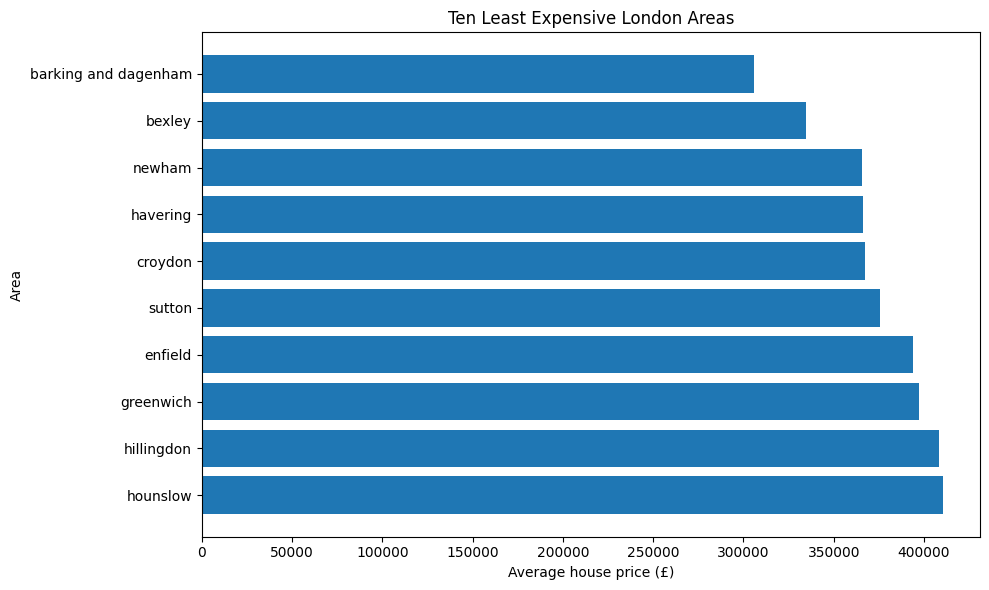

In [19]:
bottom10_latest = latest_prices.tail(10).sort_values(
    'average_price',
    ascending=False
)

plt.figure(figsize=(10, 6))

plt.barh(
    bottom10_latest['area'],
    bottom10_latest['average_price']
)

plt.title('Ten Least Expensive London Areas')
plt.xlabel('Average house price (£)')
plt.ylabel('Area')
plt.tight_layout()
plt.show()



The latest-price rankings demonstrate substantial geographical differences across London. The most expensive areas have considerably higher average property prices than the least expensive areas.

Unlike rankings based on the full-period average, this comparison represents the relative market position of areas at the end of the study period. However, the results describe area-level averages and do not represent the price of every individual property within each borough.

In [ ]:
borough_growth = (
    borough_df.sort_values('date')
    .groupby('area')
    .agg(
        start_date=('date', 'first'),
        end_date=('date', 'last'),
        start_price=('average_price', 'first'),
        end_price=('average_price', 'last')
    )
)

borough_growth['total_growth_pct'] = (
    (
        borough_growth['end_price']
        / borough_growth['start_price']
    ) - 1
) * 100

borough_growth['years'] = (
    (
        borough_growth['end_date']
        - borough_growth['start_date']
    ).dt.days / 365.25
)

borough_growth['cagr_pct'] = (
    (
        borough_growth['end_price']
        / borough_growth['start_price']
    ) ** (1 / borough_growth['years']) - 1
) * 100

display(
    borough_growth.sort_values(
        'cagr_pct',
        ascending=False
    ).head(10)
)

,start_date,end_date,start_price,end_price,total_growth_pct,years,cagr_pct
area,,,,,,,
hackney,2001-01-01,2019-11-01,139102,562039,304.05,18.83,7.70
waltham forest,2001-01-01,2019-11-01,108104,435963,303.28,18.83,7.69
barking and dagenham,2001-01-01,2019-11-01,82343,305882,271.47,18.83,7.22
lewisham,2001-01-01,2019-11-01,112637,417318,270.50,18.83,7.20
haringey,2001-01-01,2019-11-01,154406,561283,263.51,18.83,7.09
newham,2001-01-01,2019-11-01,101578,365400,259.72,18.83,7.03
greenwich,2001-01-01,2019-11-01,115168,397157,244.85,18.83,6.79
westminster,2001-01-01,2019-11-01,282566,955615,238.19,18.83,6.68
southwark,2001-01-01,2019-11-01,154901,512367,230.77,18.83,6.56


### Fastest price growth

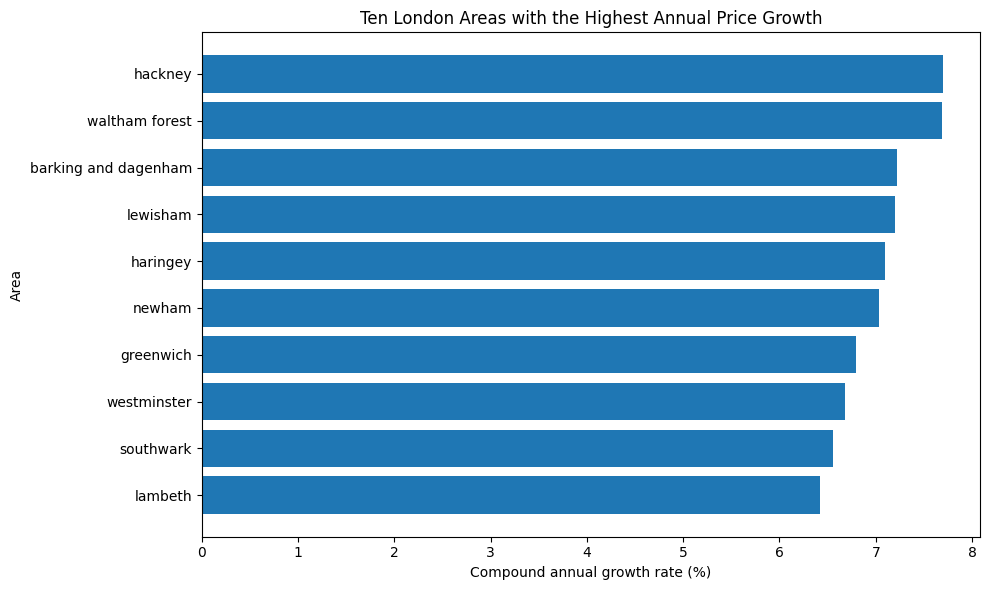

In [21]:
top_growth = (
    borough_growth
    .sort_values('cagr_pct', ascending=False)
    .head(10)
    .sort_values('cagr_pct')
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_growth.index,
    top_growth['cagr_pct']
)

plt.title('Ten London Areas with the Highest Annual Price Growth')
plt.xlabel('Compound annual growth rate (%)')
plt.ylabel('Area')
plt.tight_layout()
plt.show()



The compound annual growth rate compares the average yearly rate of price appreciation across areas. The ranking may differ from the latest-price ranking because an area can experience rapid growth while remaining relatively affordable.

Growth rankings should be interpreted alongside the starting price and period covered. A high percentage increase from a low initial value does not necessarily mean that the area became one of London's most expensive markets.

In [22]:
selected_areas = [
    'kensington and chelsea',
    'westminster',
    'camden',
    'croydon',
    'barking and dagenham'
]

selected_areas = [
    area for area in selected_areas
    if area in borough_df['area'].unique()
]

selected_data = borough_df[
    borough_df['area'].isin(selected_areas)
]

### Selected borough price trends

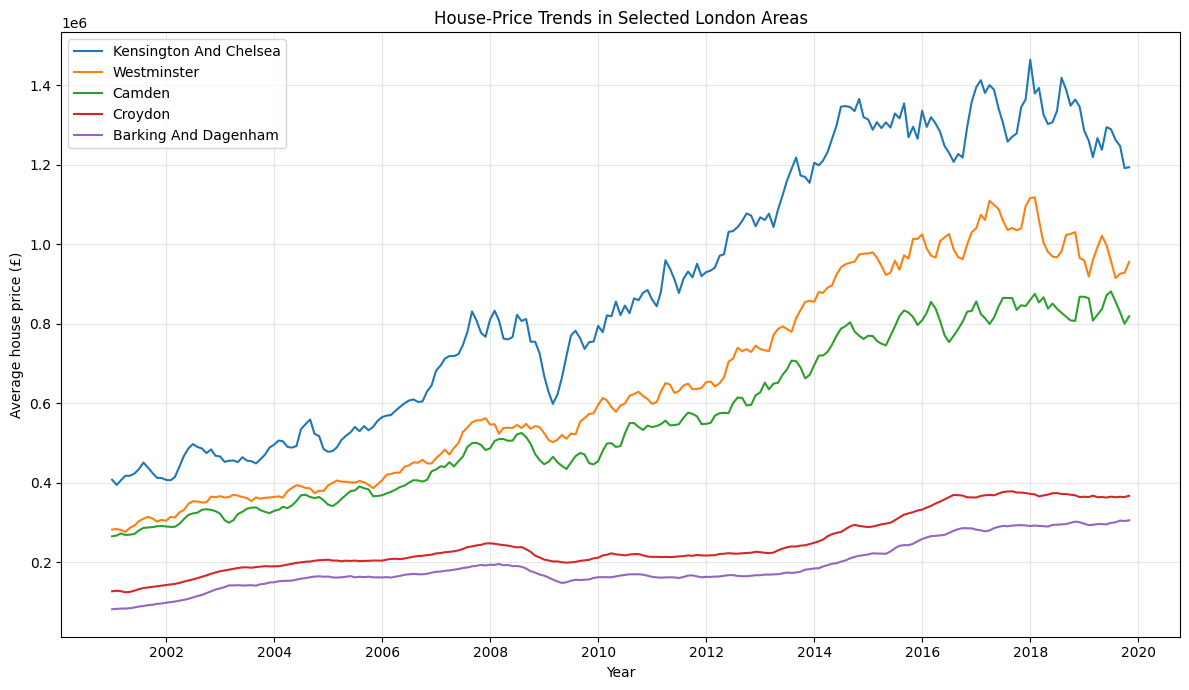

In [51]:
plt.figure(figsize=(12, 7))

for area in selected_areas:
    area_data = selected_data[
        selected_data['area'] == area
    ]

    plt.plot(
        area_data['date'],
        area_data['average_price'],
        label=area.title()
    )

plt.title('House-Price Trends in Selected London Areas')
plt.xlabel('Year')
plt.ylabel('Average house price (£)')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()



The selected-area comparison shows that London boroughs did not follow identical price paths. Although most areas experienced long-term nominal growth, their price levels, growth rates and responses to market disruption differed.

The distance between the series provides an initial visual indication of spatial inequality. A widening distance suggests that expensive and affordable areas may have diverged over time.

###Price index for fair trend comparison

In [24]:
borough_df['area_start_price'] = (
    borough_df.groupby('area')['average_price']
    .transform('first')
)

borough_df['price_index'] = (
    borough_df['average_price']
    / borough_df['area_start_price']
) * 100

display(
    borough_df[
        ['date', 'area', 'average_price', 'price_index']
    ].head()
)

,date,area,average_price,price_index
0,2001-01-01,barking and dagenham,82343,100.00
1,2001-02-01,barking and dagenham,83266,101.12
2,2001-03-01,barking and dagenham,84058,102.08
3,2001-04-01,barking and dagenham,83965,101.97
4,2001-05-01,barking and dagenham,85124,103.38


### Indexed growth trends

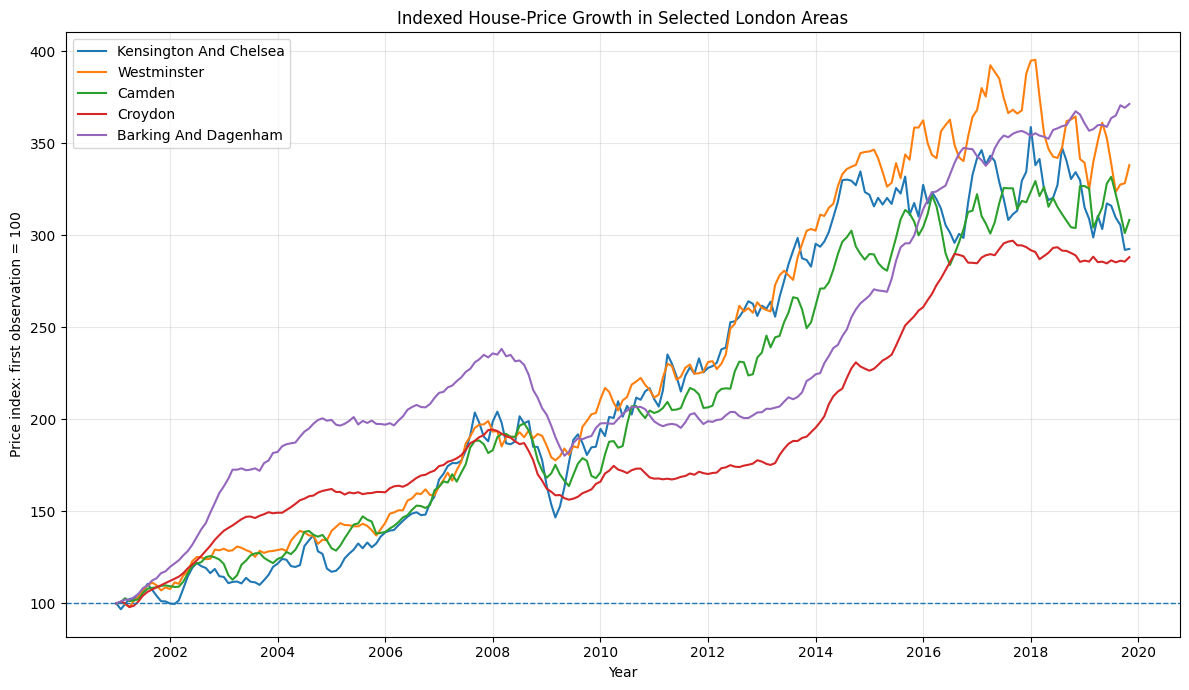

In [50]:
plt.figure(figsize=(12, 7))

for area in selected_areas:
    area_data = borough_df[
        borough_df['area'] == area
    ]

    plt.plot(
        area_data['date'],
        area_data['price_index'],
        label=area.title()
    )

plt.axhline(
    100,
    linestyle='--',
    linewidth=1
)

plt.title('Indexed House-Price Growth in Selected London Areas')
plt.xlabel('Year')
plt.ylabel('Price index: first observation = 100')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

100 means the starting price

150 means 50% above the starting price

300 means three times the starting price

In [26]:
annual_borough = (
    borough_df.groupby(['year', 'area'])
    .agg(
        annual_price=('average_price', 'mean'),
        annual_real_price=('real_price_2015', 'mean'),
        annual_sales=('houses_sold', 'sum')
    )
    .reset_index()
)

display(annual_borough.head())

,year,area,annual_price,annual_real_price,annual_sales
0,2001,barking and dagenham,"88,664.00","132,217.37","3,203.00"
1,2001,barnet,"185,563.33","276,731.46","6,803.00"
2,2001,bexley,"116,527.08","173,777.60","5,270.00"
3,2001,brent,"157,287.33","234,557.11","4,725.00"
4,2001,bromley,"162,131.83","241,783.31","7,522.00"


In [27]:
annual_inequality = (
    annual_borough.groupby('year')
    .agg(
        minimum_price=('annual_price', 'min'),
        maximum_price=('annual_price', 'max'),
        mean_price=('annual_price', 'mean'),
        median_price=('annual_price', 'median'),
        price_std=('annual_price', 'std')
    )
    .reset_index()
)

annual_inequality['absolute_gap'] = (
    annual_inequality['maximum_price']
    - annual_inequality['minimum_price']
)

annual_inequality['max_min_ratio'] = (
    annual_inequality['maximum_price']
    / annual_inequality['minimum_price']
)

annual_inequality['coefficient_of_variation'] = (
    annual_inequality['price_std']
    / annual_inequality['mean_price']
)

display(annual_inequality.head())
display(annual_inequality.tail())

,year,minimum_price,maximum_price,mean_price,median_price,price_std,absolute_gap,max_min_ratio,coefficient_of_variation
0,2001,"88,664.00","420,129.50","176,844.42","162,505.92","66,835.78","331,465.50",4.74,0.38
1,2002,"112,221.92","460,382.33","204,275.63","186,646.08","70,563.05","348,160.42",4.10,0.35
2,2003,"142,499.00","460,490.50","227,436.41","207,901.58","64,887.44","317,991.50",3.23,0.29
3,2004,"158,176.00","512,186.67","246,573.45","222,917.67","70,803.92","354,010.67",3.24,0.29
4,2005,"163,360.92","520,206.25","254,749.66","228,852.92","72,921.74","356,845.33",3.18,0.29


,year,minimum_price,maximum_price,mean_price,median_price,price_std,absolute_gap,max_min_ratio,coefficient_of_variation
14,2015,"233,460.08","1,302,102.75","475,043.93","429,973.29","220,902.80","1,068,642.67",5.58,0.47
15,2016,"273,919.75","1,276,235.17","512,590.97","466,785.12","206,518.98","1,002,315.42",4.66,0.40
16,2017,"287,734.83","1,344,539.75","528,783.64","477,677.75","217,516.61","1,056,804.92",4.67,0.41
17,2018,"295,196.67","1,363,880.08","525,559.48","472,979.04","214,534.23","1,068,683.42",4.62,0.41
18,2019,"299,064.91","1,249,444.27","515,066.96","461,035.50","196,406.47","950,379.36",4.18,0.38


### Price gap over time

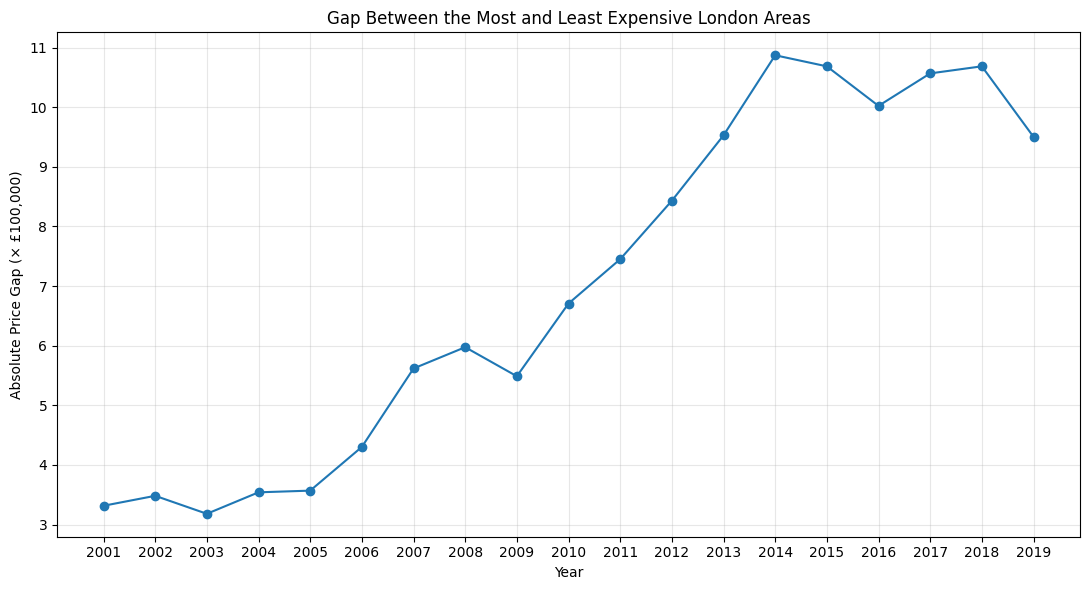

In [53]:
plt.figure(figsize=(11, 6))

plt.plot(
    annual_inequality['year'],
    annual_inequality['absolute_gap'] / 100000,
    marker='o'
)

plt.title('Gap Between the Most and Least Expensive London Areas')

plt.xlabel('Year')
plt.ylabel('Absolute Price Gap (× £100,000)')

plt.xticks(
    annual_inequality['year'].astype(int),
    rotation=0
)

plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()



The absolute price gap measures the monetary difference between the highest and lowest borough-level annual average prices. An increasing gap indicates that the difference in pounds between expensive and affordable areas widened.

However, because house prices generally increased over time, the absolute gap may grow even when proportional inequality remains stable. The ratio and coefficient of variation therefore provide important complementary measures.

### Maximum-to-minimum ratio

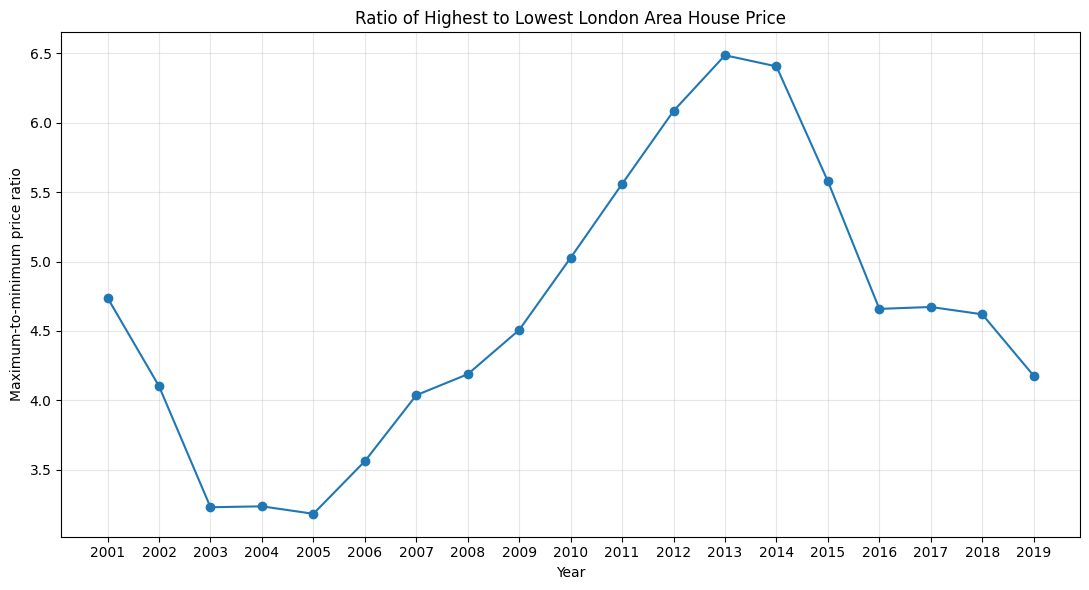

In [56]:
plt.figure(figsize=(11, 6))

plt.plot(
    annual_inequality['year'],
    annual_inequality['max_min_ratio'],
    marker='o'
)
plt.xticks(
    annual_inequality['year'].astype(int),
    rotation=0
)


plt.title(
    'Ratio of Highest to Lowest London Area House Price'
)
plt.xlabel('Year')
plt.ylabel('Maximum-to-minimum price ratio')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Relative dispersion across boroughs

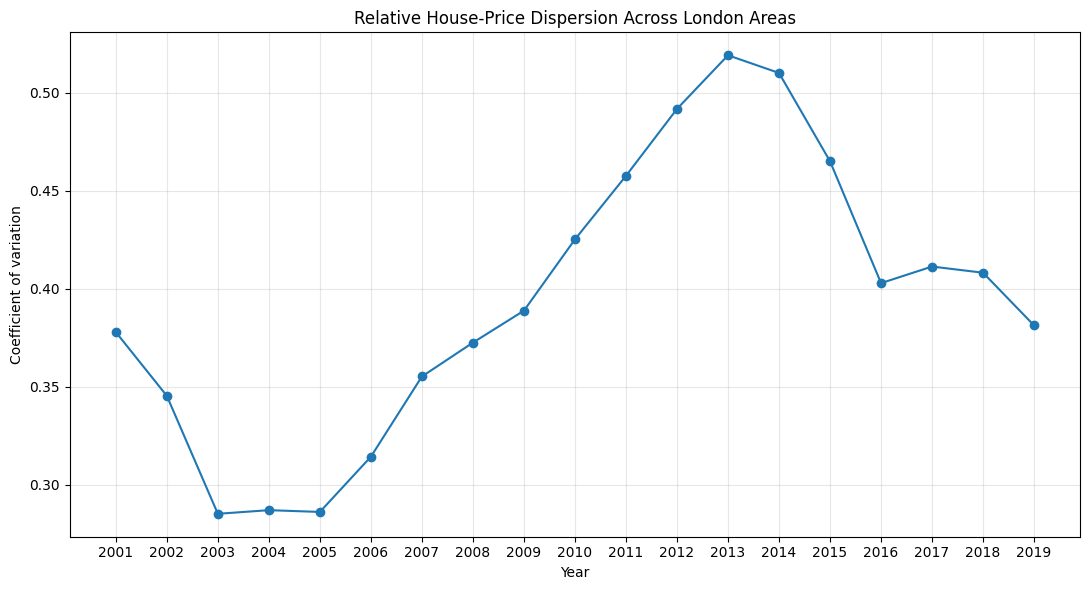

In [57]:
plt.figure(figsize=(11, 6))

plt.plot(
    annual_inequality['year'],
    annual_inequality['coefficient_of_variation'],
    marker='o'
)
plt.xticks(
    annual_inequality['year'].astype(int),
    rotation=0
)


plt.title('Relative House-Price Dispersion Across London Areas')
plt.xlabel('Year')
plt.ylabel('Coefficient of variation')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()



The coefficient of variation measures the standard deviation of borough prices relative to their mean. It therefore evaluates proportional dispersion rather than the absolute monetary gap.

A higher coefficient indicates that borough-level prices are more dispersed relative to the London average. This measure is more suitable than the absolute gap for investigating whether spatial inequality changed proportionally over time.

In [31]:
annual_quartiles = (
    annual_borough.groupby('year')['annual_price']
    .quantile([0.25, 0.50, 0.75])
    .unstack()
    .reset_index()
)

annual_quartiles.columns = [
    'year',
    'q1_price',
    'median_price',
    'q3_price'
]

annual_quartiles['iqr'] = (
    annual_quartiles['q3_price']
    - annual_quartiles['q1_price']
)

display(annual_quartiles.head())

,year,q1_price,median_price,q3_price,iqr
0,2001,"135,713.17","162,505.92","185,563.33","49,850.17"
1,2002,"159,790.92","186,646.08","220,746.17","60,955.25"
2,2003,"187,815.75","207,901.58","251,212.83","63,397.08"
3,2004,"201,829.25","222,917.67","271,649.67","69,820.42"
4,2005,"209,547.25","228,852.92","279,459.67","69,912.42"


### Interquartile range

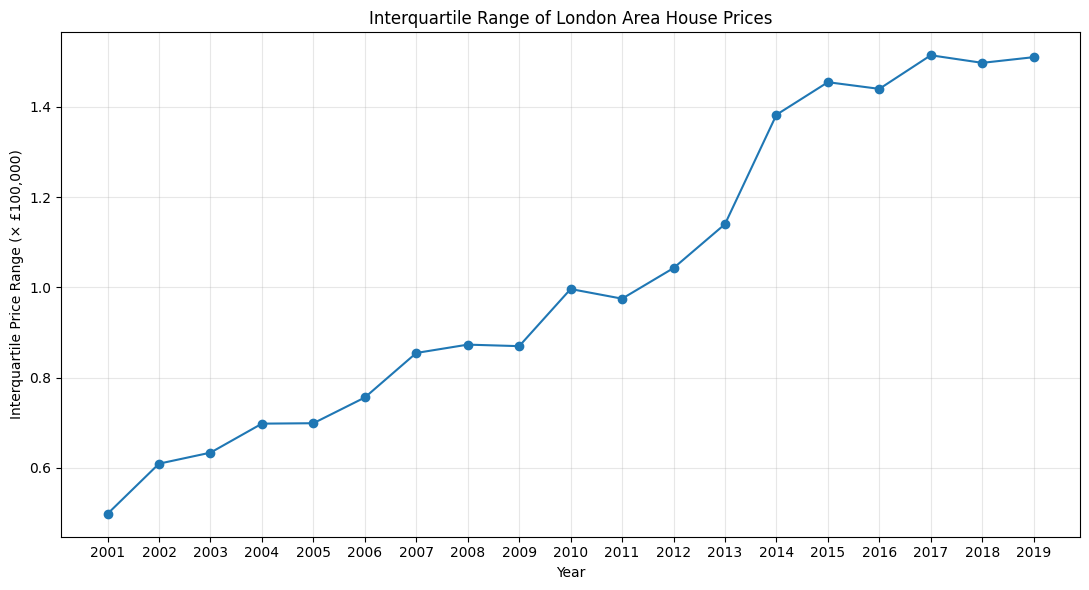

In [60]:
plt.figure(figsize=(11, 6))

plt.plot(
    annual_quartiles['year'],
    annual_quartiles['iqr'] / 100000,
    marker='o'
)

plt.title('Interquartile Range of London Area House Prices')

plt.xlabel('Year')
plt.ylabel('Interquartile Price Range (× £100,000)')

plt.xticks(
    annual_quartiles['year'].astype(int),
    rotation=0
)

plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()

### Distribution of London Area House Prices Over Time

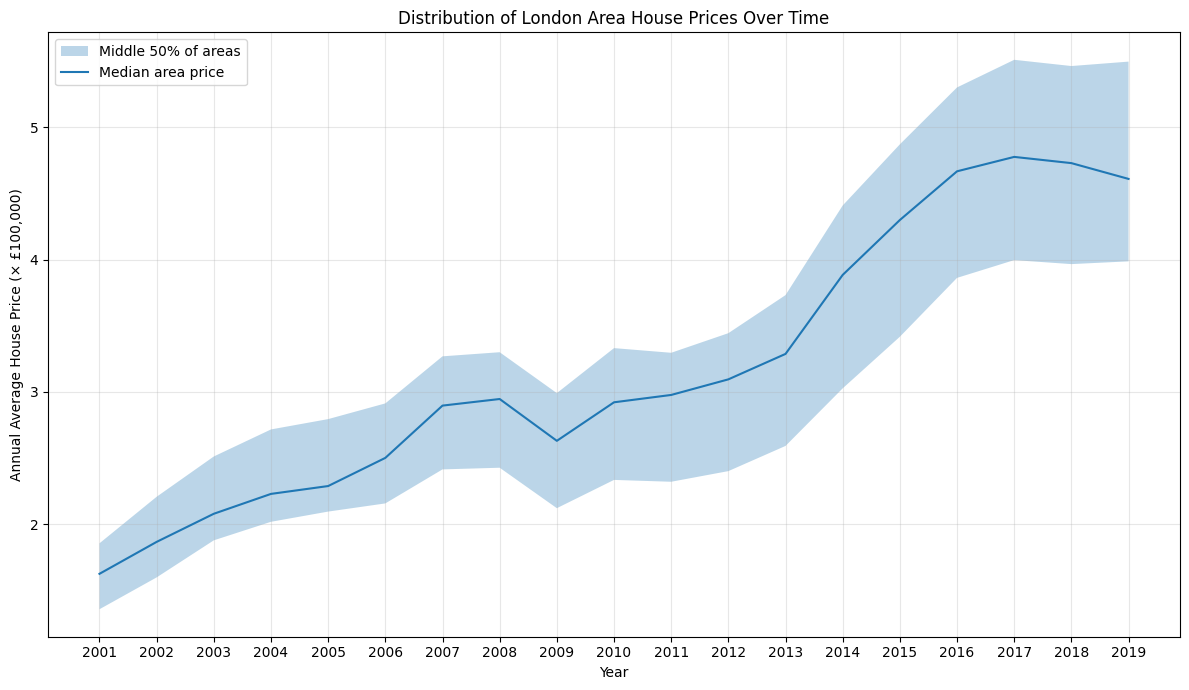

In [63]:
plt.figure(figsize=(12, 7))

plt.fill_between(
    annual_quartiles['year'],
    annual_quartiles['q1_price'] / 100000,
    annual_quartiles['q3_price'] / 100000,
    alpha=0.3,
    label='Middle 50% of areas'
)

plt.plot(
    annual_quartiles['year'],
    annual_quartiles['median_price'] / 100000,
    label='Median area price'
)

plt.title('Distribution of London Area House Prices Over Time')

plt.xlabel('Year')
plt.ylabel('Annual Average House Price (× £100,000)')

plt.xticks(
    annual_quartiles['year'].astype(int),
    rotation=0
)

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()



The shaded region represents the middle 50% of borough-level annual house prices. A widening band indicates increasing dispersion among typical London areas, while the median line shows the general movement of the central borough price.

This chart is less influenced by the most extreme high- and low-price areas than a maximum-to-minimum comparison.

In [34]:
real_inequality = (
    annual_borough.groupby('year')
    .agg(
        minimum_real_price=('annual_real_price', 'min'),
        maximum_real_price=('annual_real_price', 'max'),
        mean_real_price=('annual_real_price', 'mean'),
        real_price_std=('annual_real_price', 'std')
    )
    .reset_index()
)

real_inequality['real_absolute_gap'] = (
    real_inequality['maximum_real_price']
    - real_inequality['minimum_real_price']
)

real_inequality['real_coefficient_of_variation'] = (
    real_inequality['real_price_std']
    / real_inequality['mean_real_price']
)

inequality_comparison = annual_inequality.merge(
    real_inequality,
    on='year',
    how='inner'
)

### Norminal and real price gaps

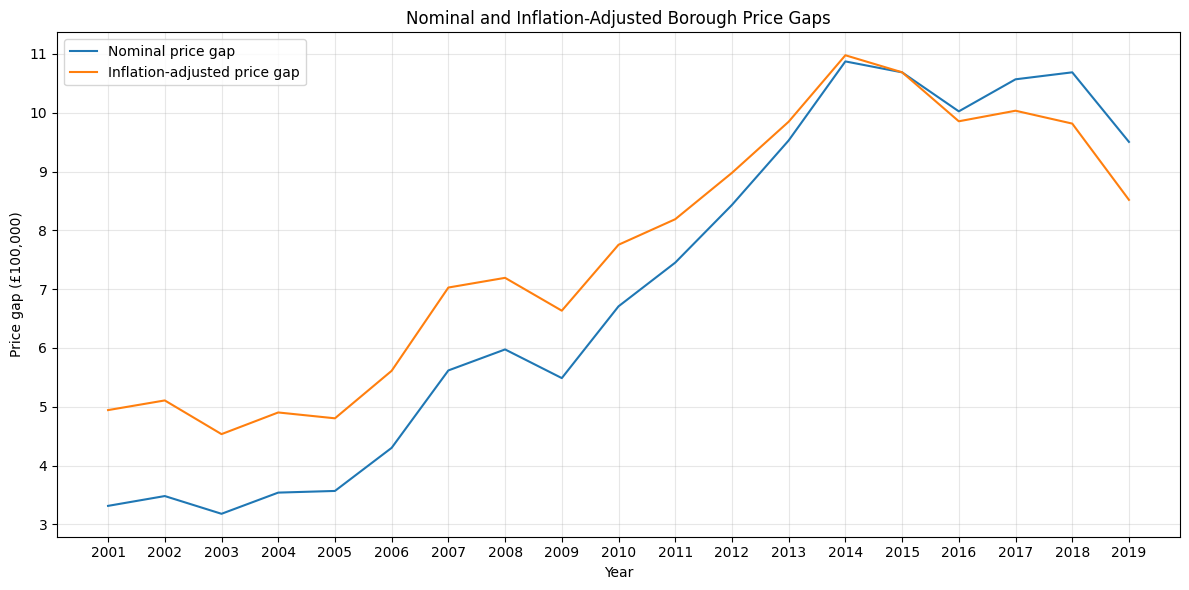

In [66]:
plt.figure(figsize=(12, 6))

plt.plot(
    inequality_comparison['year'],
    inequality_comparison['absolute_gap'] / 100000,
    label='Nominal price gap'
)

plt.plot(
    inequality_comparison['year'],
    inequality_comparison['real_absolute_gap'] / 100000,
    label='Inflation-adjusted price gap'
)

plt.xticks(
    annual_quartiles['year'].astype(int),
    rotation=0
)

plt.title('Nominal and Inflation-Adjusted Borough Price Gaps')
plt.xlabel('Year')
plt.ylabel('Price gap (£100,000)')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Overall, the chart shows that house-price inequality between London boroughs widened substantially over time. Inflation explains part of the difference, but the increase remains clear even after adjusting for inflation.”

In [36]:
#Analyse pre- and post-2008 borough growth

borough_df['market_period'] = np.select(
    [
        borough_df['year'] <= 2007,
        borough_df['year'] >= 2009
    ],
    [
        'Pre-2008',
        'Post-2008'
    ],
    default='Transition year'
)

period_df = borough_df[
    borough_df['market_period'] != 'Transition year'
].copy()

period_prices = (
    period_df.groupby(['area', 'market_period'])
    ['average_price']
    .mean()
    .unstack()
)

period_prices['change_pct'] = (
    (
        period_prices['Post-2008']
        / period_prices['Pre-2008']
    ) - 1
) * 100

display(
    period_prices.sort_values(
        'change_pct',
        ascending=False
    ).head(10)
)

market_period,Post-2008,Pre-2008,change_pct
area,,,
westminster,"833,908.08","389,895.10",113.88
kensington and chelsea,"1,127,374.58","531,154.57",112.25
hackney,"430,148.74","217,716.11",97.57
camden,"694,342.34","356,760.74",94.62
southwark,"406,957.57","217,448.06",87.15
islington,"536,509.74","288,000.61",86.29
lambeth,"409,808.09","222,518.93",84.17
haringey,"429,014.09","233,252.08",83.93
hammersmith and fulham,"644,382.08","352,981.07",82.55


In [37]:
#Compare annual growth before and after 2008

annual_borough = annual_borough.sort_values(
    ['area', 'year']
)

annual_borough['annual_growth_pct'] = (
    annual_borough.groupby('area')['annual_price']
    .pct_change() * 100
)

annual_borough['market_period'] = np.where(
    annual_borough['year'] <= 2007,
    'Pre-2008',
    np.where(
        annual_borough['year'] >= 2009,
        'Post-2008',
        'Transition'
    )
)

growth_by_period = (
    annual_borough[
        annual_borough['market_period'] != 'Transition'
    ]
    .groupby(['area', 'market_period'])
    ['annual_growth_pct']
    .mean()
    .unstack()
)

growth_by_period['growth_difference'] = (
    growth_by_period['Post-2008']
    - growth_by_period['Pre-2008']
)

display(
    growth_by_period.sort_values(
        'growth_difference',
        ascending=False
    ).head(10)
)

market_period,Post-2008,Pre-2008,growth_difference
area,,,
city of london,8.03,9.91,-1.88
camden,5.03,9.09,-4.06
westminster,5.59,9.75,-4.16
southwark,5.29,10.00,-4.71
richmond upon thames,4.53,9.36,-4.83
kingston upon thames,4.51,9.49,-4.98
ealing,4.63,9.63,-5.01
bromley,4.45,9.47,-5.02
islington,4.91,9.96,-5.05


In [38]:
annual_sales = (
    borough_df.groupby(['year', 'area'])
    ['houses_sold']
    .sum()
    .reset_index()
)

borough_sales_summary = (
    annual_sales.groupby('area')
    .agg(
        mean_annual_sales=('houses_sold', 'mean'),
        sales_std=('houses_sold', 'std'),
        minimum_sales=('houses_sold', 'min'),
        maximum_sales=('houses_sold', 'max')
    )
    .sort_values(
        'mean_annual_sales',
        ascending=False
    )
)

display(borough_sales_summary.head(10))



,mean_annual_sales,sales_std,minimum_sales,maximum_sales
area,,,,
wandsworth,"6,242.53","1,698.08","3,726.00","9,349.00"
bromley,"5,802.37","1,545.02","3,729.00","8,367.00"
croydon,"5,558.05","1,808.14","3,347.00","8,504.00"
barnet,"5,038.89","1,380.55","3,023.00","7,315.00"
lambeth,"4,554.11","1,307.30","2,364.00","6,620.00"
enfield,"4,243.63","1,766.03","2,262.00","7,237.00"
lewisham,"4,207.53","1,339.61","2,096.00","6,133.00"
tower hamlets,"4,130.89","1,030.96","2,017.00","5,794.00"
ealing,"4,108.95","1,512.63","2,248.00","6,482.00"


### Highest transaction activity

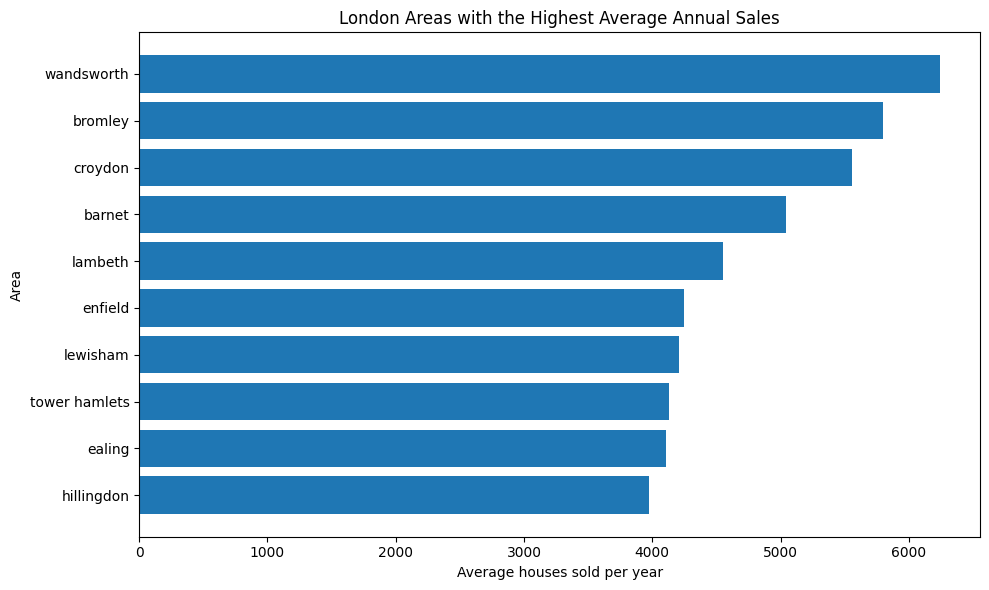

In [39]:
top_sales = (
    borough_sales_summary
    .head(10)
    .sort_values('mean_annual_sales')
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_sales.index,
    top_sales['mean_annual_sales']
)

plt.title('London Areas with the Highest Average Annual Sales')
plt.xlabel('Average houses sold per year')
plt.ylabel('Area')
plt.tight_layout()
plt.show()

In [40]:
growth_sales = (
    borough_growth[
        ['total_growth_pct', 'cagr_pct']
    ]
    .join(
        borough_sales_summary[
            ['mean_annual_sales']
        ]
    )
    .dropna()
)

### Growth vs Sales

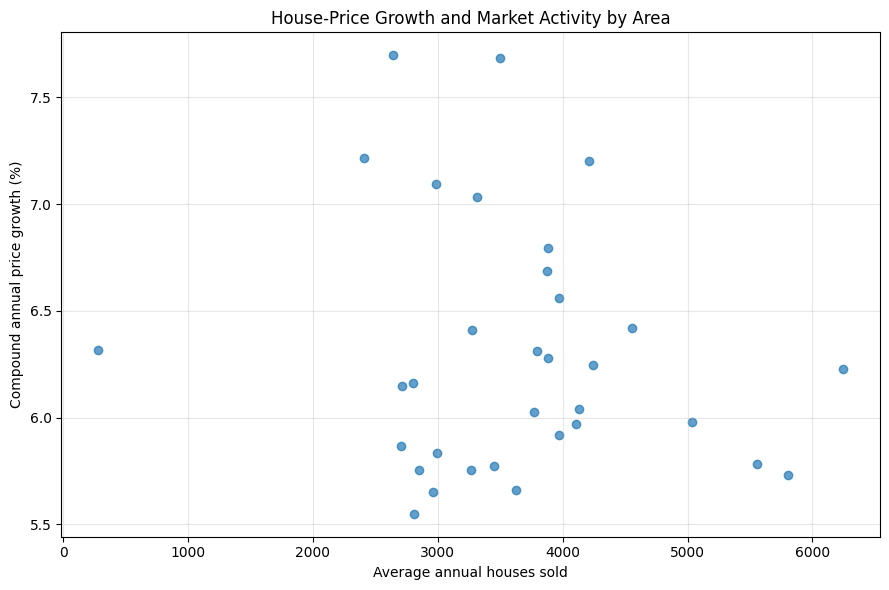

In [41]:
plt.figure(figsize=(9, 6))

plt.scatter(
    growth_sales['mean_annual_sales'],
    growth_sales['cagr_pct'],
    alpha=0.7
)

plt.title('House-Price Growth and Market Activity by Area')
plt.xlabel('Average annual houses sold')
plt.ylabel('Compound annual price growth (%)')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Areas with more house sales do not always have faster house-price growth.
The chart compares the number of houses sold with yearly house-price growth across London areas. The dots do not form a clear upward pattern, so selling more houses does not necessarily lead to faster price growth. Some areas with medium sales had the highest growth, while some areas with very high sales had only average or low growth. This suggests that other factors, such as location, demand, income and housing supply, may be more important.

In [42]:
growth_sales[
    ['mean_annual_sales', 'cagr_pct']
].corr()

,mean_annual_sales,cagr_pct
mean_annual_sales,1.00,-0.16
cagr_pct,-0.16,1.00




The scatter plot examines whether areas with greater transaction activity also experienced stronger long-term price growth. The relationship should be interpreted as an association only.

Transaction volumes may be influenced by borough population, housing-stock size, property type and data coverage. Therefore, a high number of sales does not necessarily indicate stronger demand on a per-property basis.

In [43]:
borough_growth_volatility = (
    annual_borough.groupby('area')
    ['annual_growth_pct']
    .agg(
        mean_annual_growth='mean',
        growth_volatility='std',
        minimum_growth='min',
        maximum_growth='max'
    )
    .sort_values(
        'growth_volatility',
        ascending=False
    )
)

display(borough_growth_volatility.head(10))

,mean_annual_growth,growth_volatility,minimum_growth,maximum_growth
area,,,,
city of london,8.23,12.52,-10.27,28.16
barking and dagenham,7.47,10.45,-16.50,26.98
newham,7.37,9.80,-15.13,26.38
waltham forest,7.80,9.46,-12.00,24.65
kensington and chelsea,6.61,9.07,-10.15,24.86
tower hamlets,5.98,8.55,-13.34,23.68
croydon,6.11,8.32,-13.68,18.50
havering,6.48,8.27,-11.02,20.16
redbridge,6.40,7.93,-11.97,20.19


#Figure 14 — Most volatile borough growth

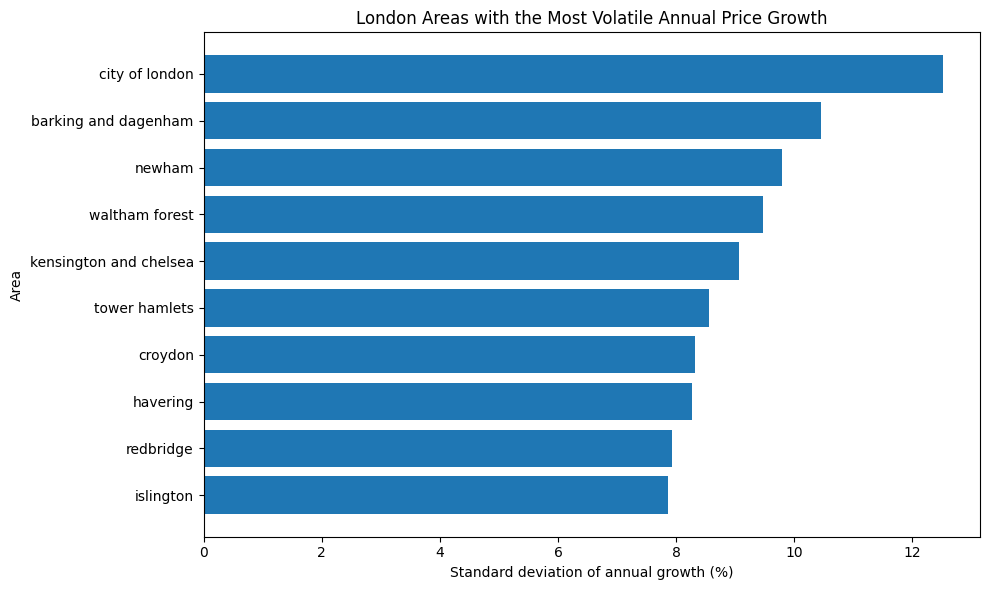

In [44]:
top_volatility = (
    borough_growth_volatility
    .head(10)
    .sort_values('growth_volatility')
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_volatility.index,
    top_volatility['growth_volatility']
)

plt.title('London Areas with the Most Volatile Annual Price Growth')
plt.xlabel('Standard deviation of annual growth (%)')
plt.ylabel('Area')
plt.tight_layout()
plt.show()

### Annual House-Price Growth in Selected London Area

In [45]:
heatmap_areas = latest_prices.head(10)['area'].tolist()

heatmap_data = (
    annual_borough[
        annual_borough['area'].isin(heatmap_areas)
    ]
    .pivot(
        index='area',
        columns='year',
        values='annual_growth_pct'
    )
)

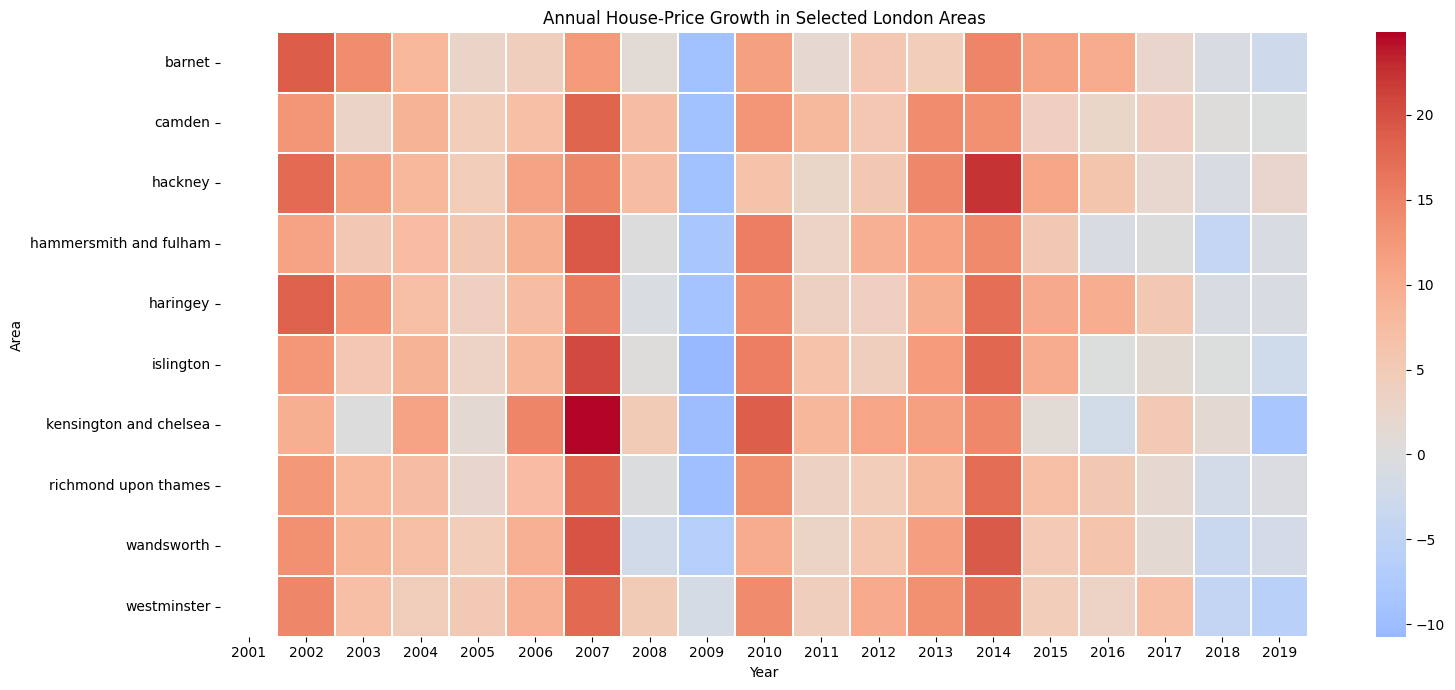

In [46]:
plt.figure(figsize=(16, 7))

sns.heatmap(
    heatmap_data,
    cmap='coolwarm',
    center=0,
    linewidths=0.3
)

plt.title('Annual House-Price Growth in Selected London Areas')
plt.xlabel('Year')
plt.ylabel('Area')
plt.tight_layout()
plt.show()



The heatmap highlights periods of positive and negative annual price growth across selected areas. Similar colour patterns across boroughs indicate common London-wide market movements, whereas differences between rows suggest borough-specific responses.

The heatmap is descriptive and does not identify the causes of individual growth or decline periods.

In [47]:
#Calculate borough ranking changes
annual_borough['price_rank'] = (
    annual_borough.groupby('year')['annual_price']
    .rank(
        method='min',
        ascending=False
    )
)

start_year = annual_borough['year'].min()
end_year = annual_borough['year'].max()

start_ranks = (
    annual_borough[
        annual_borough['year'] == start_year
    ]
    [['area', 'price_rank', 'annual_price']]
    .rename(
        columns={
            'price_rank': 'start_rank',
            'annual_price': 'start_annual_price'
        }
    )
)

end_ranks = (
    annual_borough[
        annual_borough['year'] == end_year
    ]
    [['area', 'price_rank', 'annual_price']]
    .rename(
        columns={
            'price_rank': 'end_rank',
            'annual_price': 'end_annual_price'
        }
    )
)

rank_change = start_ranks.merge(
    end_ranks,
    on='area',
    how='inner'
)

rank_change['rank_change'] = (
    rank_change['start_rank']
    - rank_change['end_rank']
)
display(
    rank_change.sort_values(
        'rank_change',
        ascending=False
    ).head(10)
)

,area,start_rank,start_annual_price,end_rank,end_annual_price,rank_change
10,hackney,21.00,"153,406.42",8.00,"558,129.64",13.00
29,waltham forest,30.00,"118,843.42",20.00,"429,904.91",10.00
21,lewisham,29.00,"121,333.08",22.00,"409,306.27",7.00
12,haringey,14.00,"165,127.08",9.00,"546,909.55",5.00
3,brent,19.00,"157,287.33",15.00,"478,074.45",4.00
26,southwark,16.00,"164,486.25",13.00,"498,608.18",3.00
20,lambeth,15.00,"164,684.75",12.00,"507,197.18",3.00
23,newham,32.00,"108,763.08",30.00,"364,124.91",2.00
24,redbridge,23.00,"141,587.50",21.00,"412,500.36",2.00
22,merton,13.00,"167,046.08",11.00,"507,536.09",2.00


In [48]:
final_borough_table = (
    borough_summary[
        [
            'mean_price',
            'median_price',
            'coefficient_of_variation',
            'mean_houses_sold'
        ]
    ]
    .join(
        borough_growth[
            [
                'start_price',
                'end_price',
                'total_growth_pct',
                'cagr_pct'
            ]
        ]
    )
    .join(
        borough_growth_volatility[
            [
                'mean_annual_growth',
                'growth_volatility'
            ]
        ]
    )
)

final_borough_table = final_borough_table.sort_values(
    'end_price',
    ascending=False
)

display(final_borough_table.head(15))

final_borough_table.to_csv(
    'week4_borough_comparison_summary.csv'
)

,mean_price,median_price,coefficient_of_variation,mean_houses_sold,start_price,end_price,total_growth_pct,cagr_pct,mean_annual_growth,growth_volatility
area,,,,,,,,,,
kensington and chelsea,"888,639.07","832,753.00",0.38,226.21,407739,1193336,192.67,5.87,6.61,9.07
westminster,"654,077.12","599,540.00",0.39,324.07,282566,955615,238.19,6.68,6.94,6.81
camden,"559,213.34","524,202.00",0.35,234.71,265515,818880,208.41,6.16,6.52,6.43
hammersmith and fulham,"527,594.00","501,662.00",0.32,235.25,259723,718071,176.48,5.55,5.79,7.22
richmond upon thames,"451,974.00","426,903.00",0.31,303.67,230335,649756,182.09,5.66,5.87,6.93
islington,"436,635.84","408,596.00",0.34,226.93,204628,629164,207.47,6.15,6.34,7.85
wandsworth,"409,200.41","381,421.00",0.33,522.50,192543,600835,212.05,6.23,6.25,7.20
hackney,"345,281.43","306,799.00",0.39,220.74,139102,562039,304.05,7.70,7.68,7.34
haringey,"349,932.92","319,010.00",0.36,249.82,154406,561283,263.51,7.09,7.11,7.21


In [49]:
annual_inequality.to_csv(
    'week4_annual_price_inequality.csv',
    index=False
)

annual_quartiles.to_csv(
    'week4_annual_price_quartiles.csv',
    index=False
)

annual_borough.to_csv(
    'week4_annual_borough_data.csv',
    index=False
)

The advanced exploratory analysis showed clear differences in house prices, growth, price changes and transaction activity across London areas.

The ranking of boroughs based on the latest house prices was different from the ranking based on long-term average prices. This shows that the time period used for comparison can affect the results. For this reason, indexed price series were also used to compare how much house prices grew over time without being affected by their starting price levels.

Price inequality across London was examined using several measures. The maximum-to-minimum price gap showed the difference in pounds between the most and least expensive areas. The maximum-to-minimum ratio and coefficient of variation were used to examine relative differences. The interquartile range was also included because it gives a more stable measure of the price differences across the middle 50% of London areas and is less affected by extremely expensive boroughs.

Nominal and inflation-adjusted house prices were compared to understand how much of the price increase may be related to general inflation and how much represents an increase in real housing values. Differences in borough-level price growth and housing market activity were also explored. However, these findings are descriptive and do not prove that one factor directly caused another.

The analysis also showed that London areas did not experience the same price patterns over time, including around the 2008 financial crisis. These differences suggest that location and time are important when modelling London house prices. Therefore, area effects and time-aware validation were considered in the following statistical and predictive modelling stages.

# Limitations of the Advanced Exploratory Data Analysis

Borough-level average house prices conceal variation between individual properties, neighbourhoods and property types.

Long-term borough comparisons may be affected by differences in data availability, including different starting dates and missing observations.

Houses-sold totals are partly influenced by the size of the local housing stock and borough population, which may limit direct comparison between areas.

CPI and Bank Rate vary over time but not across London boroughs. Therefore, their ability to explain spatial differences between boroughs is limited.

The pre- and post-2008 comparisons are descriptive and should not be interpreted as evidence that the financial crisis directly caused the observed changes.

Extremely high-priced boroughs can strongly influence maximum-to-minimum price comparisons. For this reason, more robust measures, such as the interquartile range, were also examined.

Crime was not emphasised in this stage because of concerns regarding data quality and the interpretation of zero values.